<center><h1>bagai_sanchit_HW6_extra</h1></center>

Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033382623

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Extra Practice:

## 6. ISLR 5.4.2

a) $1 - \frac{1}{n}$. Each draw picks 1 out of $n$ observations. So the probability that $j$th observation is picked first is $\frac{1}{n}$.

b) $1 - \frac{1}{n}$. Draws are made with replacement so the probability of picking the $j$th observation remains the same.

c) The $n$ draws are independent and the $j$th observation would be absent if it isn't drawn in any draw. So the probability is $(1 - \frac{1}{n})^n$.

(d) n =      5: P(jth obs in bootstrap sample) = 0.6723
(e) n =    100: P(jth obs in bootstrap sample) = 0.6340
(f) n =  10000: P(jth obs in bootstrap sample) = 0.6321


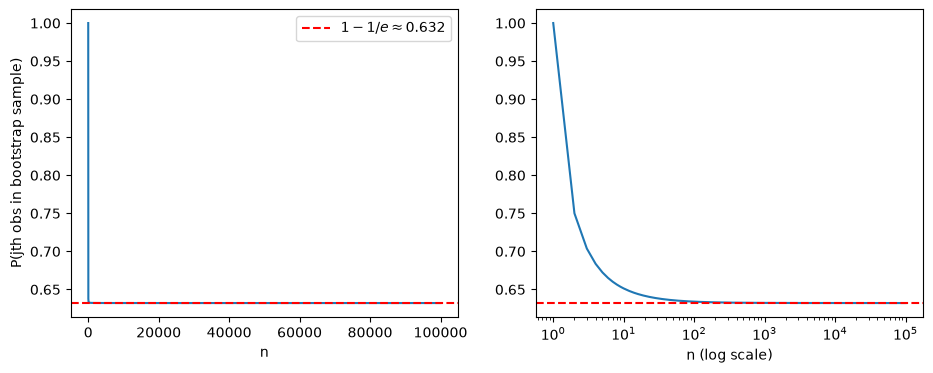

(g) The probability drops quickly from 1 at n = 1 and levels off near 0.632 = 1 - 1/e, so a bootstrap sample holds about 63% of the original observations.
(h) simulated fraction: 0.6362  vs  theoretical 0.6340
    The simulation agrees with the theory, apart from small simulation noise.


In [2]:
def p_in(n):
    return 1 - (1 - 1/n)**n

for part, n in [("d", 5), ("e", 100), ("f", 10_000)]:
    print(f"({part}) n = {n:>6}: P(jth obs in bootstrap sample) = {p_in(n):.4f}")

n = np.arange(1, 100_001)
p = p_in(n)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(n, p)
axes[0].axhline(1 - np.exp(-1), color="r", ls="--", label=r"$1-1/e \approx 0.632$")
axes[0].set_xlabel("n"); axes[0].set_ylabel("P(jth obs in bootstrap sample)"); axes[0].legend()
axes[1].semilogx(n, p)
axes[1].axhline(1 - np.exp(-1), color="r", ls="--")
axes[1].set_xlabel("n (log scale)")
plt.show()
print("(g) The probability drops quickly from 1 at n = 1 and levels off near "
      f"{1 - np.exp(-1):.3f} = 1 - 1/e, so a bootstrap sample holds about 63% of the original observations.")

rng = np.random.default_rng(10)
store = np.empty(10_000)
for i in range(10_000):
    store[i] = np.sum(rng.choice(100, 100, replace=True) == 4) > 0
print(f"(h) simulated fraction: {np.mean(store):.4f}  vs  theoretical {p_in(100):.4f}")
print("    The simulation agrees with the theory, apart from small simulation noise.")

## 7. ISLR 6.8.4

a) iii) Steadily increases.

b) ii) Decrease initially, then increase in U shape.

c) iv) Steadily decreases.

d) iii) Steadily increases.

e) v) Remains constant.

## 8. ISLR 8.4.4

a) 
```
X1 < 1 ?
├─ yes: X2 < 1 ?
│   ├─ yes: X1 < 0 ?
│   │   ├─ yes: 3
│   │   └─ no:  X2 < 0 ?
│   │            ├─ yes: 10
│   │            └─ no:  0
│   └─ no: 15
└─ no: 5
```

b) 
| Region | Mean of Y |
|---|---|
| $X_2 < 1$ and $X_1 < 1$ | $-1.80$ |
| $X_2 < 1$ and $X_1 \ge 1$ | $0.63$ |
| $1 \le X_2 < 2$ and $X_1 < 0$ | $-1.06$ |
| $1 \le X_2 < 2$ and $X_1 \ge 0$ | $0.21$ |
| $X_2 \ge 2$ | $2.49$ |


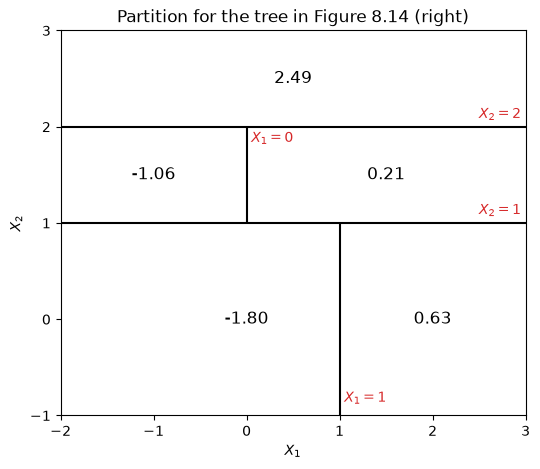

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
x_min, x_max, y_min, y_max = -2, 3, -1, 3

ax.hlines(1, x_min, x_max, colors="k")
ax.hlines(2, x_min, x_max, colors="k")
ax.vlines(1, y_min, 1, colors="k")
ax.vlines(0, 1, 2, colors="k")

ax.text(x_max - 0.05, 1.05, "$X_2 = 1$", ha="right", va="bottom", fontsize=10, color="tab:red")
ax.text(x_max - 0.05, 2.05, "$X_2 = 2$", ha="right", va="bottom", fontsize=10, color="tab:red")
ax.text(1.05, y_min + 0.1, "$X_1 = 1$", ha="left", va="bottom", fontsize=10, color="tab:red")
ax.text(0.05, 1.95, "$X_1 = 0$", ha="left", va="top", fontsize=10, color="tab:red")

ax.text(0.0, 0.0, "-1.80", ha="center", va="center", fontsize=12)
ax.text(2.0, 0.0, "0.63", ha="center", va="center", fontsize=12)
ax.text(-1.0, 1.5, "-1.06", ha="center", va="center", fontsize=12)
ax.text(1.5, 1.5, "0.21", ha="center", va="center", fontsize=12)
ax.text(0.5, 2.5, "2.49", ha="center", va="center", fontsize=12)

ax.set_xticks([-2, -1, 0, 1, 2, 3]); ax.set_yticks([-1, 0, 1, 2, 3])
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
ax.set_title("Partition for the tree in Figure 8.14 (right)")
plt.show()

## 9. ISLR 9.7.2

(The corresponding plot is under the md cell)

a) Plotted a circle centered at $(-1, 2)$ with radius of 2 units.

b) The points inside and on the curve are points where $(1 + X_1)^2 + (2 - X_2)^2 \le 4$ and outside the curve are points where $(1 + X_1)^2 + (2 - X_2)^2 > 4$.

c) (the plot depicts the predictions dots of corresponding color)
- (0, 0) => blue
- (-1, 1) => red
- (2, 2) => blue
- (3, 8) => blue

d) Expanding the equation of the curve gives us, $1 + 2X_1 - 4X_2 + X_1^2 + X_2^2 = 0$. So it's not linear in $X_1$ and $X_2$ because of the square terms, but it is linear in $X_1, X_2, X_1^2, X_2^2$.

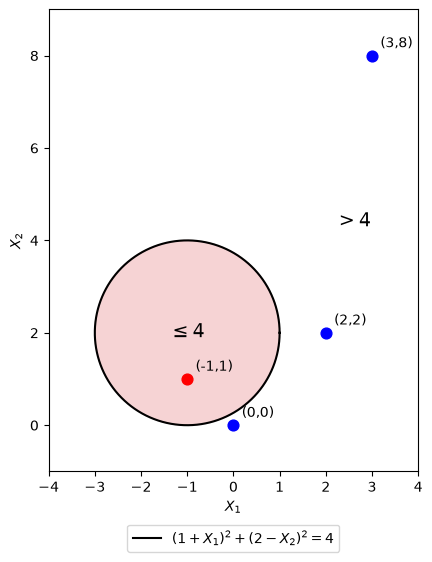

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
t = np.linspace(0, 2*np.pi, 400)
ax.plot(-1 + 2*np.cos(t), 2 + 2*np.sin(t), "k-", label=r"$(1+X_1)^2 + (2-X_2)^2 = 4$")

ax.fill(-1 + 2*np.cos(t), 2 + 2*np.sin(t), color="tab:red", alpha=0.2)
ax.text(-1, 2, r"$\leq 4$", ha="center", va="center", fontsize=14)
ax.text(2.6, 4.4, r"$> 4$", ha="center", va="center", fontsize=14)

pts = {"(0,0)": (0, 0), "(-1,1)": (-1, 1), "(2,2)": (2, 2), "(3,8)": (3, 8)}
for name, (x, y) in pts.items():
    blue = (1 + x)**2 + (2 - y)**2 > 4
    ax.scatter(x, y, c="blue" if blue else "red", s=60, zorder=3)
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(6, 6))

ax.set_xlim(-4, 4); ax.set_ylim(-1, 9); ax.set_aspect("equal")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()